# Olist E-commerce Analysis

Business analysis of the Olist Brazilian e-commerce dataset (about 99k orders, 2016 to 2018). Run all cells in order: the first cell builds a local DuckDB database from the CSVs in `data/raw/`.

## Data loading and quality checks

**Takeaway:** All 9 tables load cleanly (99,441 orders); the main issues are 814 duplicate review IDs and 2,965 orders with no delivery date, handled in the clean views below.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent  # This notebook runs from the notebooks/ folder
RAW = ROOT / "data" / "raw"
DB = ROOT / "data" / "processed" / "olist.duckdb"
REPORTS = ROOT / "reports"

DB.parent.mkdir(parents=True, exist_ok=True)  # Creates the folder if it's missing
REPORTS.mkdir(exist_ok=True)

con = duckdb.connect(str(DB))

for csv in sorted(RAW.glob("*.csv")):
    table = csv.stem.replace("_dataset", "").replace("olist_", "")
    con.execute(
        f"CREATE OR REPLACE TABLE {table} AS "
        f"SELECT * FROM read_csv_auto('{csv.as_posix()}')"
    )
    print(table, con.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0])

customers 99441
geolocation 1000163
order_items 112650
order_payments 103886
order_reviews 99224
orders 99441
products 32951
sellers 3095
product_category_name_translation 71


In [2]:
print(con.execute("DESCRIBE orders").df()[["column_name", "column_type"]])

con.execute("""
    SELECT
        COUNT(*) AS total_orders,
        COUNT(*) - COUNT(order_approved_at) AS missing_approved,
        COUNT(*) - COUNT(order_delivered_carrier_date) AS missing_carrier_date,
        COUNT(*) - COUNT(order_delivered_customer_date) AS missing_delivered
    FROM orders
""").df()

                     column_name column_type
0                       order_id     VARCHAR
1                    customer_id     VARCHAR
2                   order_status     VARCHAR
3       order_purchase_timestamp   TIMESTAMP
4              order_approved_at   TIMESTAMP
5   order_delivered_carrier_date   TIMESTAMP
6  order_delivered_customer_date   TIMESTAMP
7  order_estimated_delivery_date   TIMESTAMP


,total_orders,missing_approved,missing_carrier_date,missing_delivered
0,99441,160,1783,2965


In [3]:
display(
    con.execute("""
SELECT order_status, COUNT(*) AS orders
FROM orders GROUP BY 1 ORDER BY 2 DESC
""").df()
)

con.execute("""
    SELECT
        (SELECT COUNT(*) - COUNT(DISTINCT order_id) FROM orders) AS dup_order_ids,
        (SELECT COUNT(*) - COUNT(DISTINCT review_id) FROM order_reviews) AS dup_review_ids,
        (SELECT COUNT(*) - COUNT(DISTINCT customer_id) FROM customers) AS dup_customer_ids
""").df()

,order_status,orders
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


,dup_order_ids,dup_review_ids,dup_customer_ids
0,0,814,0


In [4]:
con.execute("""
    SELECT
        order_status,
        COUNT(*) AS orders,
        COUNT(*) FILTER (WHERE order_delivered_customer_date IS NULL) AS no_delivery_date
    FROM orders
    GROUP BY 1
    ORDER BY 2 DESC
""").df()

,order_status,orders,no_delivery_date
0,delivered,96478,8
1,shipped,1107,1107
2,canceled,625,619
3,unavailable,609,609
4,invoiced,314,314
5,processing,301,301
6,created,5,5
7,approved,2,2


In [5]:
con.execute("""
    CREATE OR REPLACE VIEW delivered_orders AS
    SELECT
        *,
        (epoch(order_delivered_customer_date) - epoch(order_purchase_timestamp)) / 86400.0
            AS delivery_days,
        date_diff('day',
                  order_estimated_delivery_date::DATE,
                  order_delivered_customer_date::DATE)
            AS days_vs_estimate   -- calendar days: positive = late, 0 = on the day, negative = early
    FROM orders
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
""")

con.execute("""
    CREATE OR REPLACE VIEW reviews_clean AS
    SELECT * EXCLUDE (rn)
    FROM (
        SELECT
            *,
            ROW_NUMBER() OVER (
                PARTITION BY order_id
                ORDER BY review_answer_timestamp DESC
            ) AS rn
        FROM order_reviews
    )
    WHERE rn = 1
""")

In [6]:
con.execute("""
    SELECT
        (SELECT COUNT(*) FROM delivered_orders) AS delivered_orders,
        (SELECT COUNT(*) FROM reviews_clean) AS reviews_clean_rows,
        (SELECT COUNT(DISTINCT order_id) FROM order_reviews) AS distinct_reviewed_orders,
        (SELECT COUNT(*) - COUNT(DISTINCT order_id) FROM reviews_clean) AS dup_orders_in_reviews
""").df()

,delivered_orders,reviews_clean_rows,distinct_reviewed_orders,dup_orders_in_reviews
0,96470,98673,98673,0


## Q1: Revenue by category and over time

Revenue = Item price excluding freight, delivered orders only.

**Takeaway:** Revenue is spread across many categories (the top 10 make up 62%) and grew through 2017, with a Black Friday spike on 24 Nov 2017 (6.6x a normal day) before levelling off in 2018.

In [7]:
top_categories = con.execute("""
    WITH items AS (
        SELECT
            COALESCE(t.product_category_name_english,
                     p.product_category_name,
                     'unknown') AS category,
            oi.order_id,
            oi.price
        FROM order_items oi
        JOIN delivered_orders d ON d.order_id = oi.order_id
        JOIN products p ON p.product_id = oi.product_id
        LEFT JOIN product_category_name_translation t
               ON t.product_category_name = p.product_category_name
    )
    SELECT
        category,
        ROUND(SUM(price), 0) AS revenue,
        COUNT(DISTINCT order_id) AS orders,
        ROUND(100 * SUM(price) / SUM(SUM(price)) OVER (), 1) AS pct_of_revenue
    FROM items
    GROUP BY category
    ORDER BY revenue DESC
    LIMIT 10
""").df()

top_categories

,category,revenue,orders,pct_of_revenue
0,health_beauty,1233132.0,8647,9.3
1,watches_gifts,1165899.0,5493,8.8
2,bed_bath_table,1023435.0,9272,7.7
3,sports_leisure,954674.0,7529,7.2
4,computers_accessories,888614.0,6529,6.7
5,furniture_decor,711928.0,6307,5.4
6,housewares,615629.0,5743,4.7
7,cool_stuff,610204.0,3559,4.6
8,auto,578849.0,3809,4.4
9,toys,471097.0,3803,3.6


In [8]:
monthly = con.execute("""
    SELECT
        date_trunc('month', d.order_purchase_timestamp)::DATE AS month,
        ROUND(SUM(oi.price), 0) AS revenue,
        COUNT(DISTINCT d.order_id) AS orders
    FROM order_items oi
    JOIN delivered_orders d ON d.order_id = oi.order_id
    GROUP BY 1
    ORDER BY 1
""").df()

monthly

,month,revenue,orders
0,2016-09-01,135.0,1
1,2016-10-01,40325.0,265
2,2016-12-01,11.0,1
3,2017-01-01,111798.0,750
4,2017-02-01,234223.0,1653
5,2017-03-01,359199.0,2546
6,2017-04-01,340670.0,2303
7,2017-05-01,489159.0,3545
8,2017-06-01,421923.0,3135
9,2017-07-01,481605.0,3872


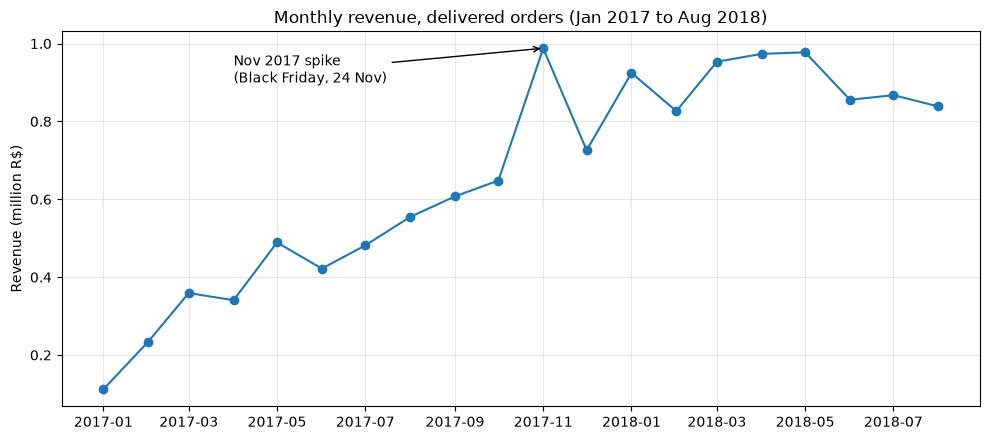

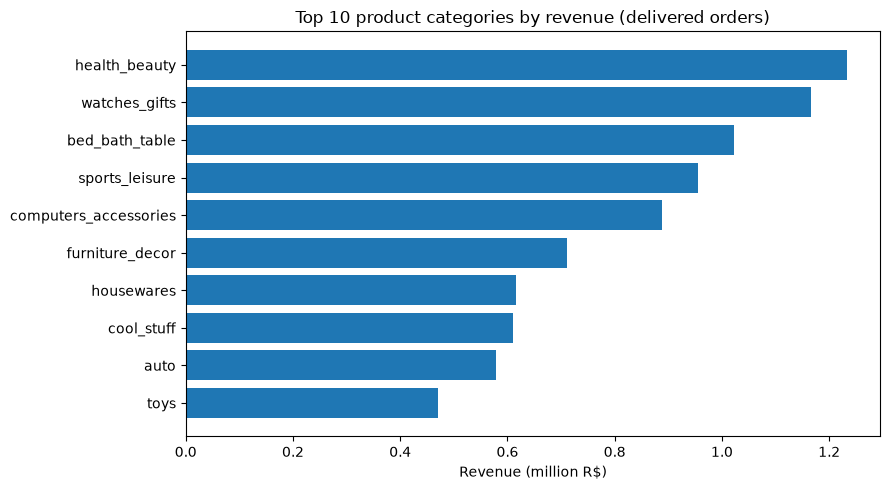

In [9]:
# --- Monthly revenue (full months only) ---
m = monthly.copy()
m["month"] = pd.to_datetime(m["month"])
m = m[(m["month"] >= "2017-01-01") & (m["month"] <= "2018-08-01")]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(m["month"], m["revenue"] / 1e6, marker="o")
ax.set_title("Monthly revenue, delivered orders (Jan 2017 to Aug 2018)")
ax.set_ylabel("Revenue (million R$)")
ax.grid(alpha=0.3)
ax.annotate(
    "Nov 2017 spike\n(Black Friday, 24 Nov)",
    xy=(pd.Timestamp("2017-11-01"), 0.988),
    xytext=(pd.Timestamp("2017-04-01"), 0.90),
    arrowprops={"arrowstyle": "->"},
)
plt.tight_layout()
plt.savefig(REPORTS / "monthly_revenue.png", dpi=150)
plt.show()

# --- Top 10 categories ---
t = top_categories.sort_values("revenue")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(t["category"], t["revenue"] / 1e6)
ax.set_title("Top 10 product categories by revenue (delivered orders)")
ax.set_xlabel("Revenue (million R$)")
plt.tight_layout()
plt.savefig(REPORTS / "top_categories.png", dpi=150)
plt.show()

24 Nov revenue: R$149,917 vs typical 1-20 Nov day: R$22,652 (6.6x)


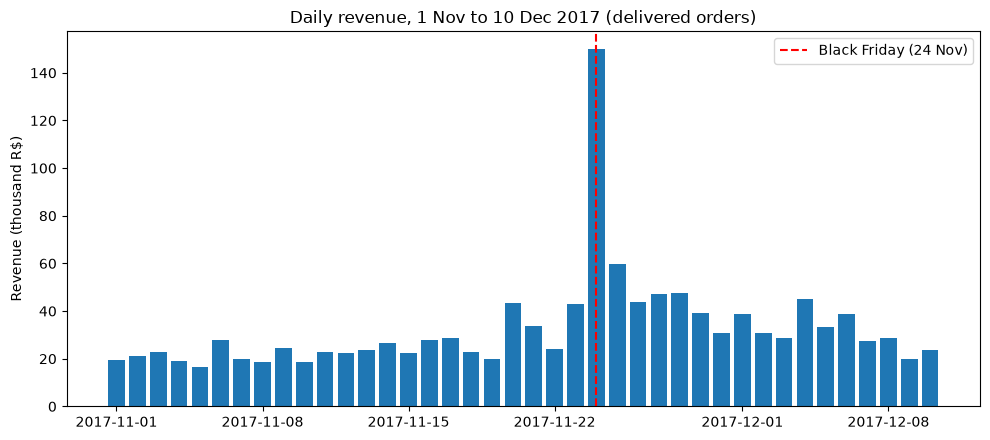

,day,revenue,orders
23,2017-11-24,149917.0,1147
24,2017-11-25,59929.0,487
27,2017-11-28,47577.0,371
26,2017-11-27,47237.0,395
33,2017-12-04,45101.0,322


In [10]:
daily = con.execute("""
    SELECT
        d.order_purchase_timestamp::DATE AS day,
        ROUND(SUM(oi.price), 0) AS revenue,
        COUNT(DISTINCT d.order_id) AS orders
    FROM order_items oi
    JOIN delivered_orders d ON d.order_id = oi.order_id
    WHERE d.order_purchase_timestamp >= '2017-11-01'
      AND d.order_purchase_timestamp <  '2017-12-11'
    GROUP BY 1
    ORDER BY 1
""").df()

daily["day"] = pd.to_datetime(daily["day"])

# How big is the spike compared with a typical early-November day?
bf = daily.loc[daily["day"] == pd.Timestamp("2017-11-24"), "revenue"].iloc[0]
baseline = daily.loc[daily["day"] <= pd.Timestamp("2017-11-20"), "revenue"].median()
print(
    f"24 Nov revenue: R${bf:,.0f} vs typical 1-20 Nov day: R${baseline:,.0f} ({bf / baseline:.1f}x)"
)

# Chart
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(daily["day"], daily["revenue"] / 1e3)
ax.axvline(
    pd.Timestamp("2017-11-24"),
    color="red",
    linestyle="--",
    label="Black Friday (24 Nov)",
)
ax.set_title("Daily revenue, 1 Nov to 10 Dec 2017 (delivered orders)")
ax.set_ylabel("Revenue (thousand R$)")
ax.legend()
plt.tight_layout()
plt.savefig(REPORTS / "black_friday_daily.png", dpi=150)
plt.show()

daily.sort_values("revenue", ascending=False).head(5)

## Q2: Delivery performance and reviews

**Takeaway:** Only 6.8% of orders arrive late, but they account for about a third of all 1 and 2 star reviews, and average scores fall from 4.29 (on time) to 1.70 (more than 7 days late).

In [11]:
# How late are deliveries typically?
con.execute("""
    SELECT
        COUNT(*) AS delivered_orders,
        ROUND(100 * AVG((days_vs_estimate > 0)::INT), 1) AS pct_late,
        ROUND(AVG(delivery_days), 1) AS avg_delivery_days,
        ROUND(median(delivery_days), 1) AS median_delivery_days,
        ROUND(median(days_vs_estimate), 1) AS median_days_vs_estimate,
        ROUND(AVG(days_vs_estimate) FILTER (WHERE days_vs_estimate > 0), 1) AS avg_days_late_when_late
    FROM delivered_orders
""").df()

,delivered_orders,pct_late,avg_delivery_days,median_delivery_days,median_days_vs_estimate,avg_days_late_when_late
0,96470,6.8,12.6,10.2,-12.0,10.6


In [12]:
# Do late deliveries get worse reviews?
by_bucket = con.execute("""
    SELECT
        CASE
            WHEN d.days_vs_estimate <= 0 THEN '1. On time or early'
            WHEN d.days_vs_estimate <= 3 THEN '2. 1 to 3 days late'
            WHEN d.days_vs_estimate <= 7 THEN '3. 4 to 7 days late'
            ELSE                              '4. Over 7 days late'
        END AS lateness,
        COUNT(*) AS orders,
        ROUND(AVG(r.review_score), 2) AS avg_review_score,
        ROUND(100 * AVG((r.review_score <= 2)::INT), 1) AS pct_low_scores
    FROM delivered_orders d
    JOIN reviews_clean r ON r.order_id = d.order_id
    GROUP BY 1
    ORDER BY 1
""").df()

by_bucket

,lateness,orders,avg_review_score,pct_low_scores
0,1. On time or early,89443,4.29,9.3
1,2. 1 to 3 days late,1852,3.29,32.1
2,3. 4 to 7 days late,1748,2.10,67.7
3,4. Over 7 days late,2781,1.70,79.3


In [13]:
con.execute("""
    SELECT
        ROUND(100.0 * AVG((d.days_vs_estimate > 0)::INT), 1) AS pct_orders_late,
        ROUND(100.0 * SUM((d.days_vs_estimate > 0)::INT * (r.review_score <= 2)::INT)
              / SUM((r.review_score <= 2)::INT), 1)          AS pct_of_low_reviews_from_late
    FROM delivered_orders d
    JOIN reviews_clean r ON r.order_id = d.order_id
""").df()

,pct_orders_late,pct_of_low_reviews_from_late
0,6.7,32.5


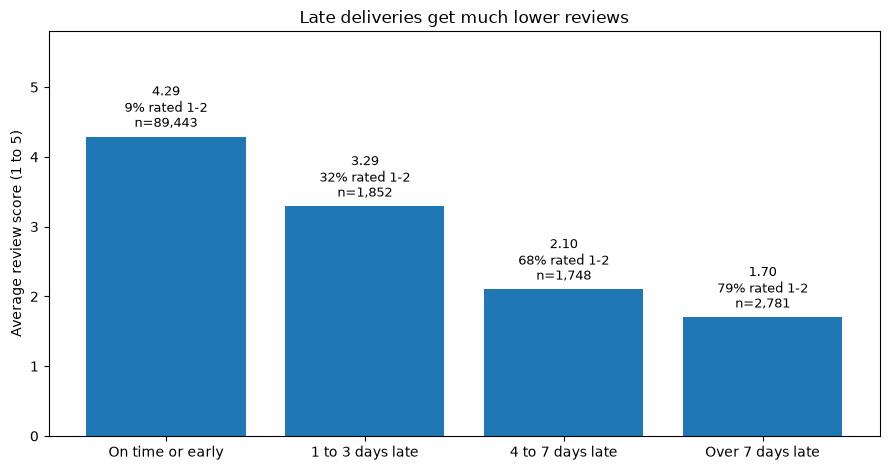

In [14]:
labels = by_bucket["lateness"].str[3:]  # strip the "1. " sort prefix

fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.bar(labels, by_bucket["avg_review_score"])
ax.set_ylim(0, 5.8)
ax.set_yticks(range(6))
ax.set_ylabel("Average review score (1 to 5)")
ax.set_title("Late deliveries get much lower reviews")
for bar, n, low in zip(bars, by_bucket["orders"], by_bucket["pct_low_scores"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.08,
        f"{bar.get_height():.2f}\n{low:.0f}% rated 1-2\nn={n:,}",
        ha="center",
        va="bottom",
        fontsize=9,
    )
plt.tight_layout()
plt.savefig(REPORTS / "delivery_vs_reviews.png", dpi=150)
plt.show()

## Q3: Customers and delivery by state

**Takeaway:** Customers are concentrated in SP, RJ and MG (66.5%), delivery is slowest in the north and northeast, and RJ plus the northeast make up about 22% of orders but about 40% of late orders.

In [15]:
# Counting unique customers by state
by_state = con.execute("""
    WITH s AS (
        SELECT
            customer_state AS state,
            COUNT(DISTINCT customer_unique_id) AS customers
        FROM customers
        GROUP BY 1
    )
    SELECT
        state,
        customers,
        ROUND(100.0 * customers / SUM(customers) OVER (), 1) AS pct_of_customers
    FROM s
    ORDER BY customers DESC
""").df()

by_state.head(10)

,state,customers,pct_of_customers
0,SP,40302,41.9
1,RJ,12384,12.9
2,MG,11259,11.7
3,RS,5277,5.5
4,PR,4882,5.1
5,SC,3534,3.7
6,BA,3277,3.4
7,DF,2075,2.2
8,ES,1964,2.0
9,GO,1952,2.0


In [16]:
delivery_by_state = con.execute("""
    SELECT
        c.customer_state AS state,
        COUNT(*) AS orders,
        ROUND(median(d.delivery_days), 1) AS median_delivery_days,
        ROUND(100 * AVG((d.days_vs_estimate > 0)::INT), 1) AS pct_late,
        SUM((d.days_vs_estimate > 0)::INT) AS late_orders,
        ROUND(AVG(r.review_score), 2) AS avg_review_score
    FROM delivered_orders d
    JOIN customers c ON c.customer_id = d.customer_id
    LEFT JOIN reviews_clean r ON r.order_id = d.order_id
    GROUP BY 1
    HAVING COUNT(*) >= 100
    ORDER BY median_delivery_days DESC
""").df()

delivery_by_state

,state,orders,median_delivery_days,pct_late,late_orders,avg_review_score
0,AM,145,25.9,2.8,4.0,4.24
1,AL,397,22.3,21.4,85.0,3.85
2,PA,946,21.1,11.2,106.0,3.91
3,MA,717,19.2,17.4,125.0,3.83
4,CE,1279,18.2,13.8,176.0,3.94
5,PB,517,18.2,10.4,54.0,4.08
6,SE,335,18.0,15.2,51.0,3.91
7,RO,243,17.6,2.9,7.0,4.17
8,BA,3256,16.9,12.2,396.0,3.93
9,PI,476,16.3,13.9,66.0,3.99


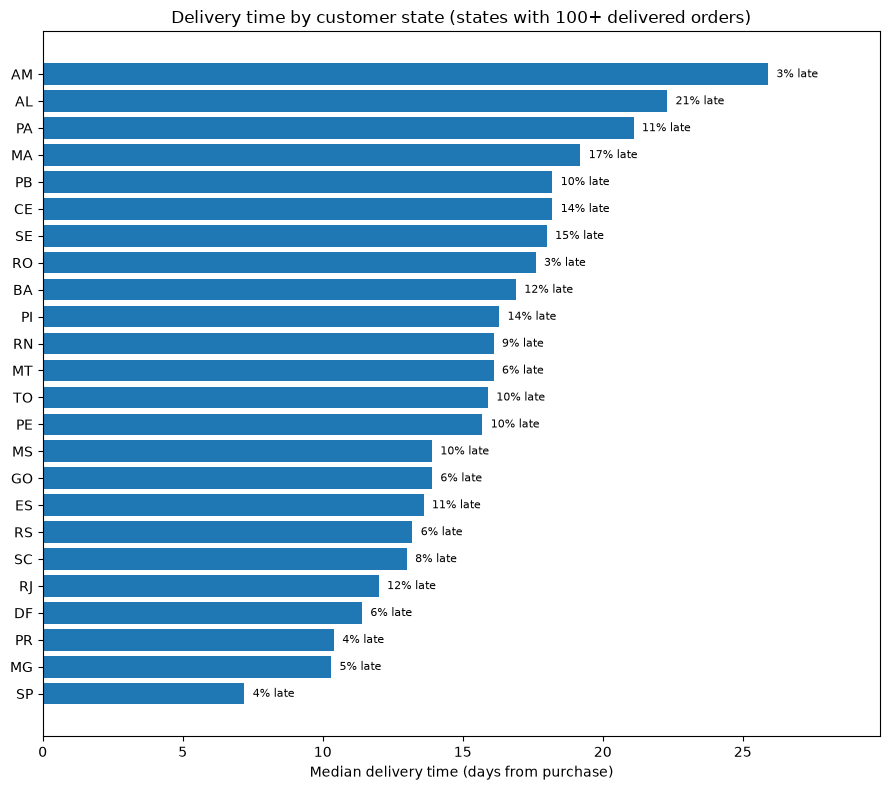

In [17]:
d = delivery_by_state.sort_values("median_delivery_days")

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(d["state"], d["median_delivery_days"])
ax.set_xlabel("Median delivery time (days from purchase)")
ax.set_title("Delivery time by customer state (states with 100+ delivered orders)")
for y, (days, late) in enumerate(zip(d["median_delivery_days"], d["pct_late"])):
    ax.text(days + 0.3, y, f"{late:.0f}% late", va="center", fontsize=8)
ax.set_xlim(0, d["median_delivery_days"].max() + 4)
plt.tight_layout()
plt.savefig(REPORTS / "delivery_by_state.png", dpi=150)
plt.show()

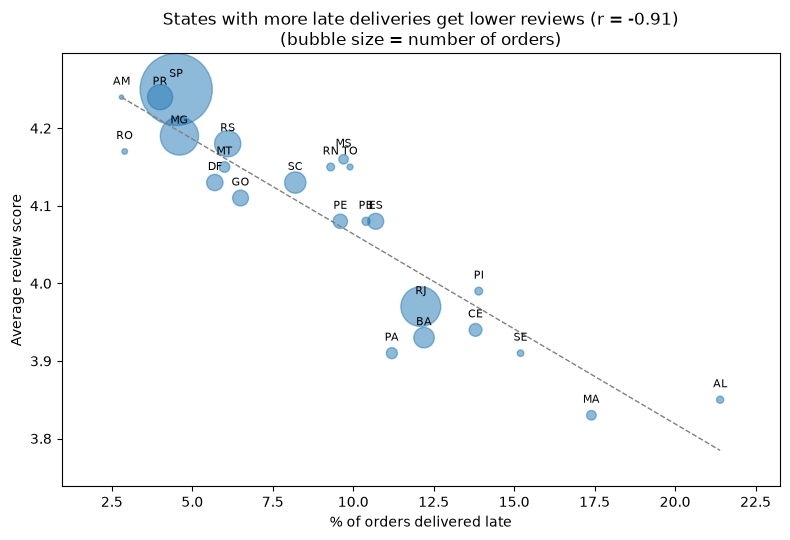

In [18]:
x = delivery_by_state["pct_late"]
y = delivery_by_state["avg_review_score"]
r = x.corr(y)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(x, y, s=delivery_by_state["orders"] / 15, alpha=0.5)

slope, intercept = np.polyfit(x, y, 1)
xs = np.linspace(x.min(), x.max(), 50)
ax.plot(xs, slope * xs + intercept, linestyle="--", color="grey", linewidth=1)

for _, row in delivery_by_state.iterrows():
    ax.annotate(
        row["state"],
        (row["pct_late"], row["avg_review_score"]),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=8,
    )

ax.margins(0.1)
ax.set_xlabel("% of orders delivered late")
ax.set_ylabel("Average review score")
ax.set_title(
    f"States with more late deliveries get lower reviews (r = {r:.2f})\n"
    "(bubble size = number of orders)"
)
plt.tight_layout()
plt.savefig(REPORTS / "late_vs_reviews_by_state.png", dpi=150)
plt.show()

In [19]:
tot_orders = delivery_by_state["orders"].sum()
tot_late = delivery_by_state["late_orders"].sum()
delivery_by_state["pct_of_orders"] = (
    100 * delivery_by_state["orders"] / tot_orders
).round(1)
delivery_by_state["pct_of_late"] = (
    100 * delivery_by_state["late_orders"] / tot_late
).round(1)

print(
    "Correlation, late rate vs avg review score:",
    delivery_by_state[["pct_late", "avg_review_score"]].corr().iloc[0, 1].round(2),
)

ne = ["MA", "PI", "CE", "RN", "PB", "PE", "AL", "SE", "BA"]
ne_rows = delivery_by_state[delivery_by_state["state"].isin(ne)]
print(
    "Northeast: % of orders",
    round(100 * ne_rows["orders"].sum() / tot_orders, 1),
    "| % of late orders",
    round(100 * ne_rows["late_orders"].sum() / tot_late, 1),
)

delivery_by_state[
    ["state", "orders", "late_orders", "pct_of_orders", "pct_of_late"]
].sort_values("pct_of_late", ascending=False).head(8)

Correlation, late rate vs avg review score: -0.91
Northeast: % of orders 9.4 | % of late orders 17.6


,state,orders,late_orders,pct_of_orders,pct_of_late
23,SP,40494,1820.0,42.1,27.9
19,RJ,12350,1495.0,12.8,22.9
22,MG,11354,519.0,11.8,8.0
8,BA,3256,396.0,3.4,6.1
17,RS,5344,325.0,5.6,5.0
18,SC,3546,291.0,3.7,4.5
16,ES,1995,214.0,2.1,3.3
21,PR,4923,199.0,5.1,3.1


## Q4: Repeat customers

**Takeaway:** 97% of customers bought only once, about 30% of repeat buyers ordered again on the same day, and one-time buyers generate 94.5% of revenue.

In [20]:
repeat = con.execute("""
    WITH per_customer AS (
        SELECT c.customer_unique_id, COUNT(*) AS orders
        FROM delivered_orders d
        JOIN customers c ON c.customer_id = d.customer_id
        GROUP BY 1
    )
    SELECT
        CASE WHEN orders >= 3 THEN '3+' ELSE CAST(orders AS VARCHAR) END AS orders_placed,
        COUNT(*)                                                         AS customers,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)              AS pct_of_customers
    FROM per_customer
    GROUP BY 1
    ORDER BY 1
""").df()

repeat

,orders_placed,customers,pct_of_customers
0,1,90549,97.0
1,2,2573,2.8
2,3+,228,0.2


In [21]:
gaps = con.execute("""
    WITH ordered AS (
        SELECT
            c.customer_unique_id,
            d.order_purchase_timestamp AS ts,
            ROW_NUMBER() OVER (PARTITION BY c.customer_unique_id
                               ORDER BY d.order_purchase_timestamp) AS n
        FROM delivered_orders d
        JOIN customers c ON c.customer_id = d.customer_id
    ),
    firsts AS (
        SELECT a.customer_unique_id,
               date_diff('day', a.ts::DATE, b.ts::DATE) AS days_to_second
        FROM ordered a
        JOIN ordered b ON a.customer_unique_id = b.customer_unique_id
                      AND a.n = 1 AND b.n = 2
    )
    SELECT
        COUNT(*) AS repeat_customers,
        ROUND(100.0 * AVG((days_to_second = 0)::INT), 1) AS pct_same_day,
        ROUND(100.0 * AVG((days_to_second <= 30)::INT), 1) AS pct_within_30_days,
        ROUND(median(days_to_second), 0) AS median_days_to_second
    FROM firsts
""").df()

gaps

,repeat_customers,pct_same_day,pct_within_30_days,median_days_to_second
0,2801,29.6,50.6,29.0


In [22]:
rev = con.execute("""
    WITH cust AS (
        SELECT
            c.customer_unique_id,
            COUNT(DISTINCT d.order_id) AS orders,
            SUM(oi.price) AS revenue
        FROM delivered_orders d
        JOIN customers c ON c.customer_id = d.customer_id
        JOIN order_items oi ON oi.order_id = d.order_id
        GROUP BY 1
    )
    SELECT
        CASE WHEN orders = 1 THEN 'One-time' ELSE 'Repeat (2+)' END AS customer_type,
        COUNT(*) AS customers,
        ROUND(SUM(revenue), 0) AS revenue,
        ROUND(100.0 * SUM(revenue) / SUM(SUM(revenue)) OVER (), 1) AS pct_of_revenue,
        ROUND(AVG(revenue), 0) AS avg_revenue_per_customer
    FROM cust
    GROUP BY 1
    ORDER BY 1
""").df()

rev

,customer_type,customers,revenue,pct_of_revenue,avg_revenue_per_customer
0,One-time,90549,12491840.0,94.5,138.0
1,Repeat (2+),2801,728409.0,5.5,260.0


## Q5: Payment methods

**Takeaway:** Credit card is used in 77% of orders and has the highest typical order value (median R$109); boleto is a distant second, and vouchers are mostly used alongside a card.

In [23]:
# Determining how often each payment method used
pay = con.execute("""
    SELECT
        p.payment_type,
        COUNT(DISTINCT p.order_id) AS orders,
        ROUND(100.0 * COUNT(DISTINCT p.order_id)
              / (SELECT COUNT(*) FROM delivered_orders), 1) AS pct_of_orders,
        ROUND(SUM(p.payment_value), 0) AS total_paid,
        ROUND(100.0 * SUM(p.payment_value)
              / SUM(SUM(p.payment_value)) OVER (), 1) AS pct_of_value
    FROM order_payments p
    JOIN delivered_orders d ON d.order_id = p.order_id
    GROUP BY 1
    ORDER BY 2 DESC
""").df()

pay

,payment_type,orders,pct_of_orders,total_paid,pct_of_value
0,credit_card,74297,77.0,12100070.0,78.5
1,boleto,19191,19.9,2769933.0,18.0
2,voucher,3679,3.8,343013.0,2.2
3,debit_card,1484,1.5,208067.0,1.3


In [ ]:
# Order value by payment method, (orders paid with a single method)
aov = con.execute("""
    WITH per_order AS (
        SELECT
            p.order_id,
            COUNT(DISTINCT p.payment_type) AS n_types,
            MIN(p.payment_type) AS payment_type,
            SUM(p.payment_value) AS order_value,
            MAX(p.payment_installments) AS installments
        FROM order_payments p
        JOIN delivered_orders d ON d.order_id = p.order_id
        GROUP BY 1
    )
    SELECT
        payment_type,
        COUNT(*) AS orders,
        ROUND(AVG(order_value), 0) AS avg_order_value,
        ROUND(median(order_value), 0) AS median_order_value,
        ROUND(AVG(installments), 1) AS avg_installments
    FROM per_order
    WHERE n_types = 1
    GROUP BY 1
    ORDER BY 2 DESC
""").df()

aov

,payment_type,orders,avg_order_value,median_order_value,avg_installments
0,credit_card,72115,166.0,109.0,3.5
1,boleto,19191,144.0,94.0,1.0
2,voucher,1498,105.0,70.0,1.0
3,debit_card,1483,140.0,90.0,1.0


In [25]:
# Determining how many orders use more than one method
con.execute("""
    SELECT
        COUNT(*) AS orders,
        SUM((n_types > 1)::INT) AS orders_with_multiple_methods
    FROM (
        SELECT p.order_id, COUNT(DISTINCT p.payment_type) AS n_types
        FROM order_payments p
        JOIN delivered_orders d ON d.order_id = p.order_id
        GROUP BY 1
    )
""").df()

,orders,orders_with_multiple_methods
0,96469,2182.0


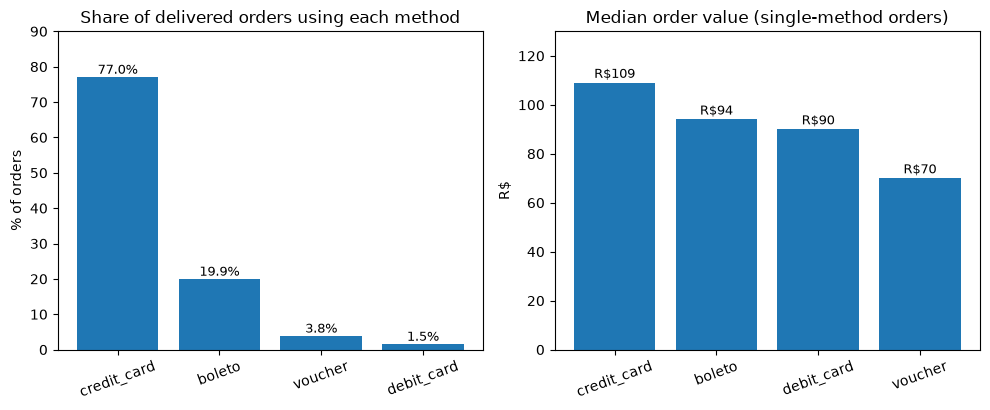

In [ ]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.2))

p = pay.sort_values("pct_of_orders", ascending=False)
a1.bar(p["payment_type"], p["pct_of_orders"])
a1.set_title("Share of delivered orders using each method")
a1.set_ylabel("% of orders")
a1.set_ylim(0, 90)
for i, v in enumerate(p["pct_of_orders"]):
    a1.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=9)

a = aov.sort_values("median_order_value", ascending=False)
a2.bar(a["payment_type"], a["median_order_value"])
a2.set_title("Median order value (single-method orders)")
a2.set_ylabel("R$")
a2.set_ylim(0, 130)
for i, v in enumerate(a["median_order_value"]):
    a2.text(i, v + 2, f"R${v:.0f}", ha="center", fontsize=9)

for ax in (a1, a2):
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(REPORTS / "payment_methods.png", dpi=150)
plt.show()